# Семинар. Поиск аномалий

Практика к лекции 5 «Поиск аномалий». Ноутбук [вдохновлён](https://github.com/esokolov/ml-course-hse/blob/master/ml2-2026-spring/homeworks-practice/homework-practice-09-imbalanced.ipynb).

## 1. Что считаем аномалией?

**Точечная** аномалия — необычный отдельный объект; **контекстная** — необычный при данных условиях; **коллективная** — необычная последовательность или группа. Ниже работаем с точечными аномалиями в транзакциях. Для остальных типов нужны признаки контекста, истории или окон последовательности.

Различаем три режима: классификация по меткам; novelty detection после обучения на нормальных объектах; обучение на смешанной выборке без меток. Здесь детекторы обучаются на смешанном train, а затем оценивают новые транзакции. Параметр LOF `novelty=True` включает API для новых объектов, но не делает train автоматически чистым.

Во всех методах **больше score = более аномально**. Score не обязательно является вероятностью. Необычная операция может быть законной, а мошенническая — выглядеть обычной.

In [2]:
from pathlib import Path
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest, HistGradientBoostingClassifier
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.metrics import (average_precision_score, roc_auc_score,
    precision_recall_curve, precision_score, recall_score, f1_score)

SEED = 67
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.grid': True})
from sklearn.preprocessing import RobustScaler
from sklearn.covariance import MinCovDet
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(SEED)
torch.set_num_threads(2)

## 2. Данные и честное разбиение

Используем [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud), как в исходном задании. `Class=1` означает мошенничество. `V1`–`V28` являются анонимизированными компонентами PCA; `Amount` содержит сумму, `Time` — секунды с начала наблюдений.

Последние 20% по времени делим поровну на validation и test. Первые 80% делим ещё на две последовательные части: первая для детекторов, вторая для обучения классификатора. Так детекторы и классификатор используют отдельные обучающие выборки.

Для скорости берём случайные 6000 объектов из первой части и 30000 из второй, без балансировки классов. Валидацию и тест оставляем целиком. 

In [3]:
data_path = Path('data/creditcard.csv')
if not data_path.exists():
    data_path.parent.mkdir(parents=True, exist_ok=True)
    url = 'https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv'
    temporary = data_path.with_suffix('.download')
    urlretrieve(url, temporary)
    temporary.replace(data_path)
df = pd.read_csv(data_path).sort_values('Time', kind='stable').reset_index(drop=True)
assert df['Class'].isin([0, 1]).all() and not df.isna().any().any()
def split_data(frame, train_fraction, val_fraction, detector_train_fraction,
               detector_size, classifier_size, seed):
    """Хронологическое разбиение и случайное сокращение только train."""
    if not (0 < train_fraction < 1 and 0 < val_fraction < 1-train_fraction):
        raise ValueError('Доли train и validation должны оставлять непустой test.')
    if not 0 < detector_train_fraction < 1:
        raise ValueError('Доля train для детекторов должна лежать между 0 и 1.')
    train_end = int(train_fraction * len(frame))
    val_end = int((train_fraction + val_fraction) * len(frame))
    detector_end = int(detector_train_fraction * train_end)
    detector = frame.iloc[:detector_end]
    classifier = frame.iloc[detector_end:train_end]
    detector = detector.sample(n=min(detector_size, len(detector)), random_state=seed)
    classifier = classifier.sample(n=min(classifier_size, len(classifier)), random_state=seed)
    return detector, classifier, frame.iloc[train_end:val_end].copy(), frame.iloc[val_end:].copy()


detector_df, classifier_df, val_df, test_df = split_data(
    df, train_fraction=0.8, val_fraction=0.1, detector_train_fraction=0.5,
    detector_size=6000, classifier_size=30000, seed=SEED,
)
parts = {'detector train': detector_df, 'classifier train': classifier_df,
         'validation': val_df, 'test': test_df}
display(pd.DataFrame({name: {'объектов': len(part), 'мошеннических': int(part.Class.sum()),
    'доля мошенничества': part.Class.mean()} for name, part in parts.items()}).T)

,объектов,мошеннических,доля мошенничества
detector train,6000.0,13.0,0.002167
classifier train,30000.0,47.0,0.001567
validation,28481.0,53.0,0.001861
test,28481.0,22.0,0.000772


### Признаки и масштаб

Убираем абсолютное время, чтобы будущее не выглядело аномальным только из-за роста счётчика. Это упрощение для точечных аномалий; часы суток и историю клиента можно было бы добавить как контекст. Сумму преобразуем через `log1p`.

Используем **RobustScaler**: медиана и межквартильный размах (IQR). Это устойчивое масштабирование, но не MAD: MAD отдельно реализуем как детектор. Все преобразования обучаются только на train детекторов.

In [4]:
def features(frame):
    result = frame[[f'V{i}' for i in range(1, 29)]].copy()
    result['log_amount'] = np.log1p(frame['Amount'])
    return result

scaler = RobustScaler().fit(features(detector_df))
X_fit = scaler.transform(features(detector_df))
X_cls = scaler.transform(features(classifier_df))
X_val = scaler.transform(features(val_df))
X_test = scaler.transform(features(test_df))
y_cls = classifier_df.Class.to_numpy()
y_val = val_df.Class.to_numpy()
y_test = test_df.Class.to_numpy()
feature_names = features(detector_df).columns.to_list()
print('Accuracy константы 0 на validation:', round(1-y_val.mean(), 5))

Accuracy константы 0 на validation: 0.99814


## 3. Известные метки: веса и балансировка

**Логистическая регрессия спрашивает:** «По известным примерам я больше похож на обычную транзакцию или на мошенническую?»

Сравним одну логистическую регрессию без коррекции, с весами классов, со случайным undersampling, oversampling и SMOTE. Валидация сохраняет исходное соотношение классов. Балансировку выполняем только на train классификатора, после обученного на train масштабирования.

| Вариант | Что делаем |
|---|---|
| Без коррекции | Обучаем на исходных данных |
| С весами классов | Увеличиваем вклад ошибок на редком классе в функцию потерь; данные не меняем |
| Undersampling | Удаляем часть обычных транзакций |
| Oversampling | Копируем мошеннические транзакции |
| SMOTE | Создаём синтетические примеры между близкими мошенническими транзакциями |

Все варианты проверяем на одной и той же валидационной выборке с исходной долей классов. Балансируем только обучающие данные.

Учебная реализация SMOTE интерполирует между соседями редкого класса. Это не гарантия реалистичности синтетической транзакции: в реальных таблицах нужно проверять ограничения признаков. Oversampling повторяет объекты, undersampling теряет часть нормы. Здесь целевая доля меньшего класса после ресемплинга — 10%, без её подбора.

Аугментация должна сохранять смысл метки. Мы не добавляем произвольный шум в банковские данные: он может нарушить связи между признаками. Синтетические точки ниже демонстрируют механику SMOTE.

In [5]:
def resample_train(X, y, method, target_fraction=0.1, n_neighbors=5, seed=42):
    if not y.mean() <= target_fraction < 1:
        raise ValueError("Целевая доля должна быть не меньше исходной и меньше 1.")
    rng = np.random.default_rng(seed)
    normal, rare = X[y == 0], X[y == 1]
    target_rare = int(np.ceil(len(normal)*target_fraction/(1-target_fraction)))
    if method == 'undersampling':
        normal = normal[rng.choice(len(normal), min(len(normal), int(len(rare)*(1-target_fraction)/target_fraction)), replace=False)]
    elif method == 'oversampling':
        extra = rare[rng.choice(len(rare), max(0, target_rare-len(rare)), replace=True)]
        rare = np.vstack([rare, extra])
    elif method == 'SMOTE':
        if len(rare) < 2:
            raise ValueError('Для SMOTE нужны хотя бы два редких объекта.')
        k = min(n_neighbors, len(rare)-1)
        indices = NearestNeighbors(n_neighbors=k+1).fit(rare).kneighbors(rare, return_distance=False)
        neighbors = np.array([row[row != i][:k] for i, row in enumerate(indices)])
        n_new = max(0, target_rare-len(rare))
        base = rng.integers(len(rare), size=n_new)
        other = neighbors[base, rng.integers(k, size=n_new)]
        synthetic = rare[base] + rng.random((n_new, 1))*(rare[other]-rare[base])
        rare = np.vstack([rare, synthetic])
    return np.vstack([normal, rare]), np.r_[np.zeros(len(normal)), np.ones(len(rare))].astype(int)

def compare_balancing(X_train, y_train, X_valid, y_valid, *,
                      modes, target_fraction, n_neighbors, threshold, seed):
    rows = []
    for mode in modes:
        train, labels = (X_train, y_train) if mode in ['без коррекции', 'веса'] else resample_train(
            X_train, y_train, mode, target_fraction, n_neighbors, seed)
        model = LogisticRegression(class_weight='balanced' if mode == 'веса' else None,
                                   max_iter=2000, random_state=seed)
        model.fit(train, labels)
        prob = model.predict_proba(X_valid)[:, 1]
        rows.append({'вариант': mode, 'размер train': len(labels), 'доля класса 1': labels.mean(),
            'validation AP': average_precision_score(y_valid, prob),
            f'precision при {threshold}': precision_score(y_valid, prob >= threshold, zero_division=0),
            f'recall при {threshold}': recall_score(y_valid, prob >= threshold, zero_division=0)})
    return pd.DataFrame(rows).set_index('вариант')


balance_results = compare_balancing(
    X_cls, y_cls, X_val, y_val,
    modes=['без коррекции', 'веса', 'undersampling', 'oversampling', 'SMOTE'],
    target_fraction=0.1, n_neighbors=5, threshold=0.5, seed=SEED,
)
display(balance_results.round(4))


,размер train,доля класса 1,validation AP,precision при 0.5,recall при 0.5
вариант,,,,,
без коррекции,30000,0.0016,0.8138,0.9286,0.7358
веса,30000,0.0016,0.8206,0.0485,0.8868
undersampling,470,0.1000,0.5434,0.1847,0.8679
oversampling,33282,0.1000,0.8345,0.3358,0.8679
SMOTE,33282,0.1000,0.8382,0.3594,0.8679


## 4. Статистические оценки

**MAD спрашивает:** «Есть ли у меня хотя бы один признак, который сильно отклоняется от типичного значения?»

**Махаланобис спрашивает:** «Насколько необычно сочетание моих признаков с учётом связей между ними?»

**MAD**: для каждого признака вычисляем медиану $m_j$ и медиану абсолютных отклонений $a_j$. Score равен $\max_j |x_j-m_j|/a_j$. При нулевом MAD используем небольшой нижний предел, чтобы явно считать отклонение от постоянного признака сильным. В других задачах такие признаки можно исключать.

**Махаланобис**: $s(x)=(x-\mu)^T\Sigma^{-1}(x-\mu)$. Используем устойчивые оценки центра и ковариации `MinCovDet`, чтобы загрязнение меньше влияло на нормальную область. Один эллипсоид плохо описывает несколько раздельных нормальных групп. Ковариация может быть почти вырожденной даже при полном ранге. Добавляем к ней $\lambda I$, где $\lambda=10^{-3}\,\mathrm{tr}(\Sigma)/d$. Это фиксированная численная регуляризация, а не параметр, подобранный по тесту.

In [6]:
class MADDetector:
    def fit(self, X):
        self.center_ = np.median(X, axis=0)
        mad = np.median(np.abs(X-self.center_), axis=0)
        self.scale_ = np.maximum(mad, 1e-9)
        return self
    def score_samples(self, X):
        return np.max(np.abs(X-self.center_) / self.scale_, axis=1)

class MahalanobisDetector:
    def fit(self, X):
        self.model_ = MinCovDet(random_state=SEED, support_fraction=.8).fit(X)
        cov = self.model_.covariance_
        ridge = max(1e-9, 1e-3*np.trace(cov)/X.shape[1])
        self.covariance_ = cov + ridge*np.eye(X.shape[1])
        self.precision_ = np.linalg.inv(self.covariance_)
        assert np.linalg.eigvalsh(self.covariance_).min() > 0
        return self
    def score_samples(self, X):
        # Квадрат расстояния с регуляризованной ковариацией.
        delta = X-self.model_.location_
        return np.einsum('ij,jk,ik->i', delta, self.precision_, delta)

## 5. kNN и LOF

**kNN спрашивает:** «Насколько далеко от меня соседи?»

**LOF спрашивает:** «Моё окружение более разреженное, чем окружение моих соседей?»

kNN использует расстояние до k-го соседа в train: большой радиус означает низкую плотность. LOF сравнивает плотность объекта с плотностями его соседей. Поэтому разреженная нормальная группа может иметь высокий kNN-score, но LOF около 1.

В LOF расстояние достижимости сглаживает слишком малые расстояния; затем вычисляется обратное среднее расстояние и отношение локальных плотностей. `-score_samples` sklearn переводит оценку к направлению «больше = аномальнее». Оцениваем только объекты, которых не было в обучении LOF.

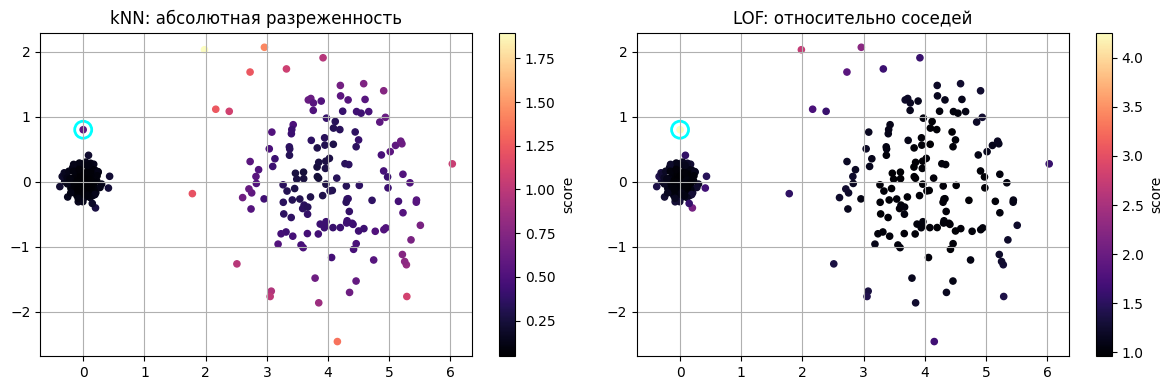

In [7]:
class KNNDetector:
    def __init__(self, k=20):
        self.k = k
    def fit(self, X):
        self.model_ = NearestNeighbors(n_neighbors=self.k, n_jobs=-1).fit(X)
        return self
    def score_samples(self, X):
        return self.model_.kneighbors(X, return_distance=True)[0][:, -1]

rng = np.random.default_rng(SEED)
local_train = np.vstack([rng.normal([0, 0], .15, (300, 2)), rng.normal([4, 0], .8, (300, 2))])
local_new = np.vstack([rng.normal([0, 0], .15, (150, 2)), rng.normal([4, 0], .8, (150, 2)), [[0, .8]]])
knn_demo = KNNDetector(20).fit(local_train)
lof_demo = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(local_train)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, score, title in zip(axes, [knn_demo.score_samples(local_new), -lof_demo.score_samples(local_new)],
                          ['kNN: абсолютная разреженность', 'LOF: относительно соседей']):
    plot = ax.scatter(*local_new.T, c=score, cmap='magma', s=20)
    ax.scatter([0], [.8], s=150, facecolors='none', edgecolors='cyan', linewidths=2)
    ax.set_title(title); fig.colorbar(plot, ax=ax, label='score')
plt.tight_layout(); plt.show()

## 6. Isolation Forest

**Isolation Forest спрашивает:** «За сколько случайных разбиений меня удаётся отделить от остальных?»

Случайные осевые разбиения изолируют объекты. Короткий путь соответствует более высокой аномальности. Лекция использует $-\bar h(x)$; нормированная оценка $2^{-\bar h(x)/c(\psi)}$ даёт то же ранжирование при фиксированном размере подвыборки $\psi$. Остаток нескольких объектов в листе учитывается поправкой к длине пути.

Используем готовый `IsolationForest` из sklearn.

## 7. PCA: ошибка восстановления

**PCA спрашивает:** «Насколько далеко я нахожусь от подпространства, описывающего основной разброс данных?»

Обучаем PCA на train, проецируем объект на r компонент и восстанавливаем его. Score — квадрат евклидовой нормы остатка. Если сохранить все компоненты, ошибка почти обнулится и детектор потеряет смысл.

PCA видит отклонения **поперёк** подпространства, но может пропустить очень далёкий объект **вдоль** него. Следующий пример показывает это ограничение. Наличие признаков `V1`–`V28` от чужого PCA не заменяет этот метод: мы обучаем собственное подпространство и оцениваем остаток.

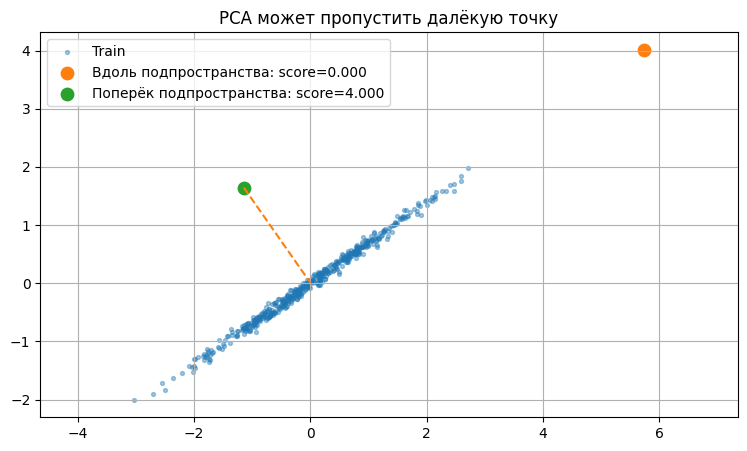

In [8]:
class PCADetector:
    def __init__(self, n_components=10):
        self.n_components = n_components
    def fit(self, X):
        self.model_ = PCA(n_components=self.n_components, svd_solver='full').fit(X)
        return self
    def score_samples(self, X):
        restored = self.model_.inverse_transform(self.model_.transform(X))
        return np.sum((X-restored)**2, axis=1)

rng = np.random.default_rng(SEED)
t = rng.normal(size=500)
pca_cloud = np.c_[t, .7*t] + rng.normal(0, .05, (500, 2))
pca_demo = PCADetector(1).fit(pca_cloud)
u = pca_demo.model_.components_[0]
center = pca_demo.model_.mean_
queries = np.array([center+7*u, center+2*np.array([-u[1], u[0]])])
restored = pca_demo.model_.inverse_transform(pca_demo.model_.transform(queries))
plt.scatter(*pca_cloud.T, s=8, alpha=.4, label='Train')
for i, label in enumerate(['Вдоль подпространства', 'Поперёк подпространства']):
    plt.scatter(*queries[i], s=80, label=f'{label}: score={pca_demo.score_samples(queries)[i]:.3f}')
    plt.plot([queries[i,0], restored[i,0]], [queries[i,1], restored[i,1]], '--')
plt.axis('equal'); plt.legend(); plt.title('PCA может пропустить далёкую точку'); plt.show()

## 8. Автоэнкодер

**Автоэнкодер спрашивает:** «Насколько хорошо сеть, обученная восстанавливать примеры из train, может восстановить меня?»

Кодировщик сжимает признаки, декодировщик восстанавливает их. Обучаем сеть по MSE; score — сумма квадратов ошибок по масштабированным координатам. Все координаты имеют одинаковые веса $w_j=1$. Для фиксированного числа признаков сумма и среднее дают одинаковое ранжирование.

Узкое скрытое представление ограничивает способность просто копировать вход. Но автоэнкодер может восстанавливать аномалии хорошо, а сложную норму плохо. Train содержит небольшую долю мошенничества, и она тоже влияет на обучение. Проверим две размерности представления по validation AP. Число эпох фиксировано, test не используется для ранней остановки или настройки.

In [9]:
class AutoencoderDetector:
    def __init__(self, latent_dim=4, hidden_dim=32, epochs=40,
                 learning_rate=1e-3, batch_size=256, seed=42):
        self.latent_dim, self.epochs, self.seed = latent_dim, epochs, seed
        self.hidden_dim = hidden_dim
        self.learning_rate, self.batch_size = learning_rate, batch_size
    def fit(self, X):
        torch.manual_seed(self.seed)
        d = X.shape[1]
        self.model_ = nn.Sequential(nn.Linear(d, self.hidden_dim), nn.ReLU(),
            nn.Linear(self.hidden_dim, self.latent_dim), nn.ReLU(),
            nn.Linear(self.latent_dim, self.hidden_dim), nn.ReLU(), nn.Linear(self.hidden_dim, d))
        optimizer = torch.optim.Adam(self.model_.parameters(), lr=self.learning_rate)
        generator = torch.Generator().manual_seed(self.seed)
        loader = DataLoader(TensorDataset(torch.as_tensor(X, dtype=torch.float32)),
                            batch_size=self.batch_size, shuffle=True, generator=generator)
        self.history_ = []
        self.model_.train()
        for epoch in range(self.epochs):
            total = 0.0
            for (batch,) in loader:
                optimizer.zero_grad()
                loss = nn.functional.mse_loss(self.model_(batch), batch)
                loss.backward()
                optimizer.step()
                total += loss.item()*len(batch)
            self.history_.append(total/len(X))
        self.model_.eval()
        return self
    def score_samples(self, X):
        scores = []
        self.model_.eval()
        with torch.no_grad():
            for start in range(0, len(X), 2048):
                batch = torch.as_tensor(X[start:start+2048], dtype=torch.float32)
                scores.append(((batch-self.model_(batch))**2).sum(dim=1).numpy())
        return np.concatenate(scores)

## 9. Настройка и выбор порога

Метрики ранжирования: Average Precision (AP) и ROC AUC. AP не равно трапецеидальной площади под PR-кривой. При редком положительном классе особенно важны precision, recall и число тревог.

Детекторы не используют метки в `fit`, но настройка по validation AP использует разметку. Для каждого семейства выбираем лучший вариант по AP, затем порог по F1 на validation. Это учебный критерий; ниже отдельно рассмотрим нагрузку на проверку. Никакой балансировки validation и test.

MAD готов


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/covariance/_robust_covariance.py:185: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-90.067566675149664 > -92.886417668719020). You may want to try with a higher value of support_fraction (current value: 0.800).
  warnings.warn(


Махаланобис готов
kNN готов
LOF готов
IF готов
PCA готов
Автоэнкодер готов


,метод,параметры,validation AP
0,MAD,median/MAD,0.020249
1,Махаланобис,MinCovDet,0.082463
2,kNN,k=20,0.037038
3,kNN,k=50,0.031855
4,LOF,k=20,0.045787
5,LOF,k=50,0.075907
6,IF,psi=128,0.054401
7,IF,psi=256,0.070160
8,PCA,r=8,0.042892
9,PCA,r=16,0.034082


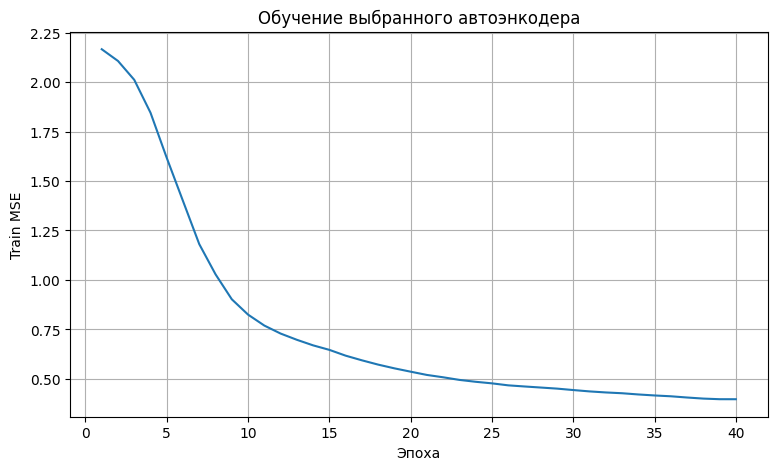

In [10]:
positive_score_types = (MADDetector, MahalanobisDetector, KNNDetector, PCADetector, AutoencoderDetector)
def anomaly_score(model, X):
    score = model.score_samples(X)
    return score if isinstance(model, positive_score_types) else -score

def fit_detectors(candidates, X_train, X_valid, y_valid):
    """Выбираем вариант каждого метода по AP на validation."""
    models, val_scores, search_rows = {}, {}, []
    for name, variants in candidates.items():
        best_ap = -1
        for setting, model in variants:
            model.fit(X_train)
            score = anomaly_score(model, X_valid)
            assert np.isfinite(score).all()
            ap = average_precision_score(y_valid, score)
            search_rows.append({'метод': name, 'параметры': setting, 'validation AP': ap})
            if ap > best_ap:
                best_ap = ap
                models[name], val_scores[name] = model, score
        print(name, 'готов')
    return models, val_scores, pd.DataFrame(search_rows)


candidates = {
    'MAD': [('median/MAD', MADDetector())],
    'Махаланобис': [('MinCovDet', MahalanobisDetector())],
    'kNN': [(f'k={k}', KNNDetector(k)) for k in (20, 50)],
    'LOF': [(f'k={k}', LocalOutlierFactor(n_neighbors=k, novelty=True, n_jobs=-1)) for k in (20, 50)],
    'IF': [(f'psi={psi}', IsolationForest(n_estimators=60, max_samples=psi, random_state=SEED, n_jobs=-1)) for psi in (128, 256)],
    'PCA': [(f'r={r}', PCADetector(r)) for r in (8, 16)],
    'Автоэнкодер': [(f'latent={r}', AutoencoderDetector(latent_dim=r, hidden_dim=32, epochs=40,
        learning_rate=1e-3, batch_size=256, seed=SEED)) for r in (4, 12)],
}
models, val_scores, search_results = fit_detectors(candidates, X_fit, X_val, y_val)
display(search_results)
plt.plot(np.arange(1, len(models['Автоэнкодер'].history_)+1), models['Автоэнкодер'].history_)
plt.xlabel('Эпоха'); plt.ylabel('Train MSE'); plt.title('Обучение выбранного автоэнкодера'); plt.show()

In [11]:
def choose_threshold(y, score):
    precision, recall, thresholds = precision_recall_curve(y, score)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1]+recall[:-1], 1e-12)
    return float(thresholds[np.argmax(f1)])

def report(y, score, threshold):
    prediction = score >= threshold
    return {'AP': average_precision_score(y, score), 'ROC AUC': roc_auc_score(y, score),
            'precision': precision_score(y, prediction, zero_division=0),
            'recall': recall_score(y, prediction, zero_division=0),
            'F1': f1_score(y, prediction, zero_division=0),
            'тревог': int(prediction.sum()), 'порог': threshold}

thresholds = {name: choose_threshold(y_val, score) for name, score in val_scores.items()}
best_name = max(val_scores, key=lambda name: average_precision_score(y_val, val_scores[name]))
print('Детектор для разбора ошибок выбран на validation:', best_name)

Детектор для разбора ошибок выбран на validation: Махаланобис


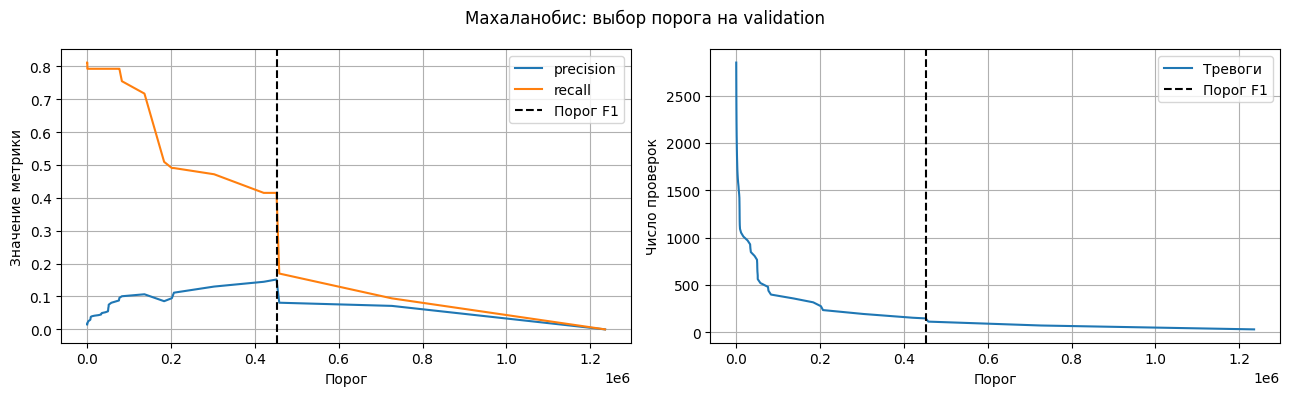

In [12]:
def plot_thresholds(y, score, selected_threshold, model_name,
                    quantile_range=(0.90, 0.999), n_points=70):
    grid = np.unique(np.r_[np.quantile(score, np.linspace(*quantile_range, n_points)), selected_threshold])
    rows = [report(y, score, threshold) for threshold in grid]
    threshold_table = pd.DataFrame(rows)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(grid, threshold_table['precision'], label='precision')
    axes[0].plot(grid, threshold_table['recall'], label='recall')
    axes[0].legend(); axes[0].set_ylabel('Значение метрики')
    axes[1].plot(grid, threshold_table['тревог'], label='Тревоги')
    axes[1].set_ylabel('Число проверок')
    for ax in axes:
        ax.axvline(selected_threshold, color='black', linestyle='--', label='Порог F1')
        ax.set_xlabel('Порог'); ax.legend()
    fig.suptitle(f'{model_name}: выбор порога на validation'); plt.tight_layout(); plt.show()


plot_thresholds(
    y_val, val_scores[best_name], selected_threshold=thresholds[best_name],
    model_name=best_name, quantile_range=(0.90, 0.999), n_points=70,
)


## 10. Финальная проверка и ошибки

Параметры и пороги зафиксированы. Сравниваем методы на будущем временном отрезке. Разбор ошибок предназначен для понимания ограничений; после него нельзя перенастраивать модель и считать этот же test независимым.

,AP,ROC AUC,precision,recall,F1,тревог,порог
MAD,0.0071,0.9129,0.0083,0.2727,0.0162,721.0,23.9235
Махаланобис,0.0337,0.9509,0.0490,0.3182,0.0848,143.0,452025.7766
kNN,0.0180,0.9284,0.0252,0.3636,0.0471,318.0,16.6726
LOF,0.0551,0.9147,0.0926,0.4545,0.1538,108.0,3.0087
IF,0.0208,0.9187,0.0325,0.4091,0.0602,277.0,0.5768
PCA,0.0113,0.9067,0.0219,0.2273,0.0400,228.0,117.3696
Автоэнкодер,0.0136,0.8860,0.0245,0.1818,0.0432,163.0,104.8158


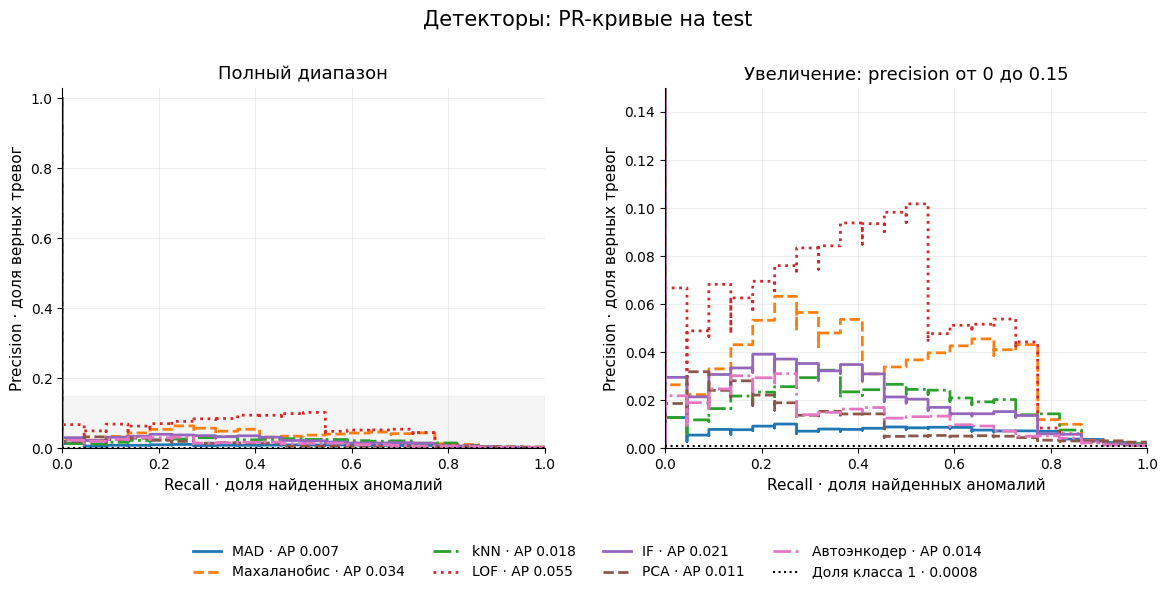

Положительных объектов в test: 22
Малое число положительных объектов делает оценки чувствительными к единичным ошибкам.


In [13]:
test_scores = {name: anomaly_score(model, X_test) for name, model in models.items()}
results = pd.DataFrame({name: report(y_test, score, thresholds[name]) for name, score in test_scores.items()}).T
display(results.round(4))
def plot_pr_curves(y, scores, zoom_precision=0.15, figsize=(14, 6)):
    """Полная PR-кривая и увеличение нижней части без изменения данных."""
    fig, axes = plt.subplots(1, 2, figsize=figsize, sharex=True)
    colors = plt.get_cmap('tab10').colors
    styles = ['-', '--', '-.', ':', '-', '--', '-.']
    for i, (name, score) in enumerate(scores.items()):
        precision, recall, _ = precision_recall_curve(y, score)
        ap = average_precision_score(y, score)
        for ax in axes:
            ax.step(recall, precision, where='post', linewidth=2,
                    color=colors[i % len(colors)], linestyle=styles[i % len(styles)],
                    label=f'{name} · AP {ap:.3f}')
    for ax in axes:
        ax.axhline(y.mean(), color='black', linestyle=':', linewidth=1.5,
                   label=f'Доля класса 1 · {y.mean():.4f}')
        ax.set_xlim(0, 1)
        ax.set_xlabel('Recall · доля найденных аномалий', fontsize=11)
        ax.set_ylabel('Precision · доля верных тревог', fontsize=11)
        ax.grid(alpha=0.22)
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].set_ylim(0, 1.03)
    axes[0].set_title('Полный диапазон', fontsize=13)
    axes[0].axhspan(0, zoom_precision, color='grey', alpha=0.08)
    axes[1].set_ylim(0, zoom_precision)
    axes[1].set_title(f'Увеличение: precision от 0 до {zoom_precision:g}', fontsize=13)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, 0.01),
               ncol=4, frameon=False, fontsize=10)
    fig.suptitle('Детекторы: PR-кривые на test', fontsize=15)
    fig.subplots_adjust(bottom=0.25, top=0.85, wspace=0.25)
    plt.show()


plot_pr_curves(y_test, test_scores, zoom_precision=0.15, figsize=(14, 6))
print('Положительных объектов в test:', int(y_test.sum()))
print('Малое число положительных объектов делает оценки чувствительными к единичным ошибкам.')

### Ложные тревоги и пропуски

Сначала посмотрим на обычные транзакции выше порога. Большие отклонения отдельных координат объясняют необычность, но не доказывают мошенничество. Затем проверим мошеннические транзакции ниже порога, как рекомендуется в лекции. Значение анонимизированных PCA-признаков нельзя напрямую перевести в экономический смысл.

,Time,Amount,Class,anomaly_score
270737,164233.0,106.78,0,8.535188e+06
263178,160833.0,5.90,0,7.287285e+06
274771,166198.0,25691.16,0,6.267154e+06


,V27,V28,V20,V7,V5
270737,-7.712179,-2.991251,21.196983,-14.225940,-1.763068
263178,-1.063984,9.059118,21.975912,-12.821957,0.098345
274771,215.696482,-190.274326,-161.919652,118.202773,-99.982713


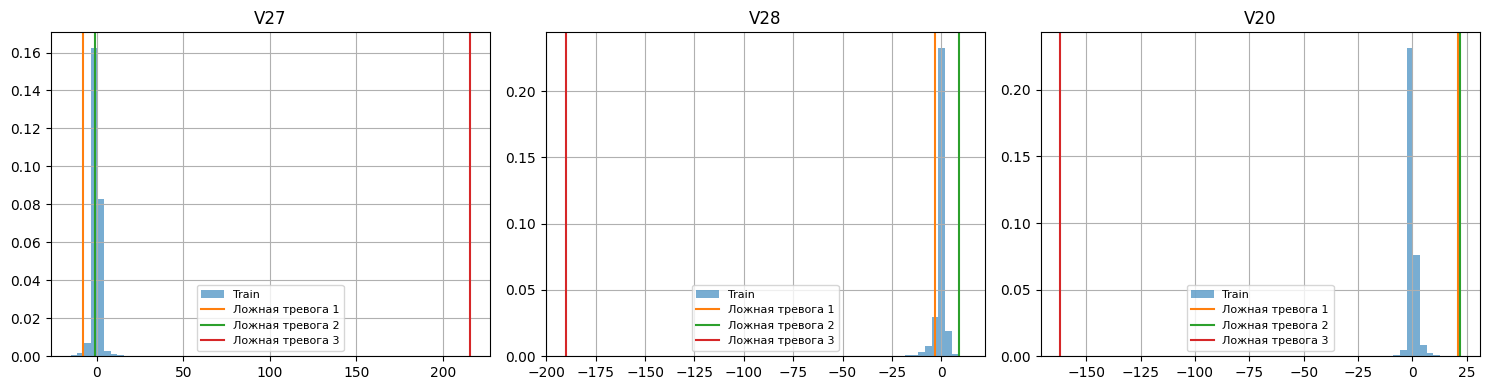

In [14]:
def show_false_positives(frame, X, y, score, X_reference, feature_names,
                         threshold, n_examples=3, n_features=5):
    false_positive = np.flatnonzero((y == 0) & (score >= threshold))
    selected = false_positive[np.argsort(score[false_positive])[::-1][:n_examples]]
    if len(selected):
        table = frame.iloc[selected][['Time', 'Amount', 'Class']].copy()
        table['anomaly_score'] = score[selected]
        display(table)
        baseline_median = np.median(X_reference, axis=0)
        deviations = np.abs(X[selected] - baseline_median)
        top = np.argsort(deviations.max(axis=0))[-n_features:][::-1]
        display(pd.DataFrame(X[selected][:, top], columns=np.array(feature_names)[top],
                             index=frame.iloc[selected].index))
        n_plots = min(3, len(top))
        fig, axes = plt.subplots(1, n_plots, figsize=(5*n_plots, 4), squeeze=False)
        axes = axes.ravel()
        for ax, feature_idx in zip(axes, top[:n_plots]):
            reference = X_reference[:, feature_idx]
            lo = min(np.quantile(reference, .005), X[selected, feature_idx].min())
            hi = max(np.quantile(reference, .995), X[selected, feature_idx].max())
            ax.hist(reference, bins=60, range=(lo, hi), density=True, alpha=.6, label='Train')
            for j, idx in enumerate(selected):
                ax.axvline(X[idx, feature_idx], color=f'C{j+1}', label=f'Ложная тревога {j+1}')
            ax.set_title(feature_names[feature_idx]); ax.legend(fontsize=8)
        plt.tight_layout(); plt.show()
    else:
        print('При выбранном пороге ложных тревог нет. Это не означает, что найдены все аномалии.')


show_false_positives(
    test_df, X_test, y_test, test_scores[best_name], X_fit, feature_names,
    threshold=thresholds[best_name], n_examples=3, n_features=5,
)


,Time,Amount,Class,score
276071,166883.0,19.95,1,82.218685
281674,170348.0,42.53,1,105.254477
263080,160791.0,1.00,1,134.084615
275992,166831.0,634.30,1,2034.725320
274382,165981.0,0.00,1,6455.499701


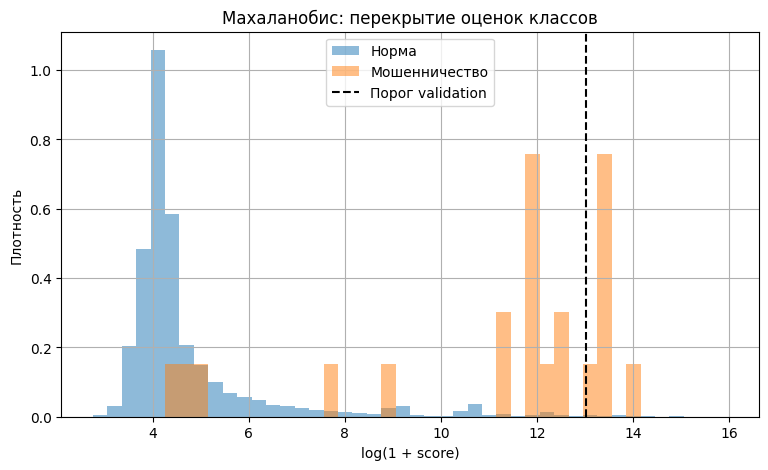

In [15]:
false_negative = np.flatnonzero((y_test == 1) & (test_scores[best_name] < thresholds[best_name]))
missed = false_negative[np.argsort(test_scores[best_name][false_negative])[:5]]
missed_table = test_df.iloc[missed][['Time', 'Amount', 'Class']].copy()
missed_table['score'] = test_scores[best_name][missed]
display(missed_table)
fig, ax = plt.subplots()
# Общие интервалы обоих классов; log1p делает широкий диапазон читаемым.
plot_score = np.log1p(test_scores[best_name])
bins = np.linspace(plot_score.min(), plot_score.max(), 45)
for label, text in [(0, 'Норма'), (1, 'Мошенничество')]:
    ax.hist(plot_score[y_test == label], bins=bins, density=True, alpha=.5, label=text)
ax.axvline(np.log1p(thresholds[best_name]), color='black', linestyle='--', label='Порог validation')
ax.set_xlabel('log(1 + score)'); ax.set_ylabel('Плотность'); ax.legend()
ax.set_title(f'{best_name}: перекрытие оценок классов'); plt.show()

### Итоги основной части

Сопоставьте AP, recall и нагрузку разных методов. Проверьте, выигрывает ли нелинейный автоэнкодер у PCA: его большая гибкость сама по себе не гарантирует лучшую детекцию. Необычность, мошенничество и ошибка восстановления — разные понятия.

Методы отражают разные предположения: MAD проверяет координаты, Махаланобис учитывает ковариацию, kNN и LOF используют окружение, IF — изолируемость, PCA и автоэнкодер — восстановимость. Разбиение по времени и выбор порога столь же важны, как выбор метода.

## Источники и вопросы

- Лекция 5 «Поиск аномалий», И. С. Никитин: порядок и обозначения основной части.
- [Практическое задание ВШЭ 2026](https://github.com/esokolov/ml-course-hse/blob/master/ml2-2026-spring/homeworks-practice/homework-practice-09-imbalanced.ipynb): исходный материал для семинара.
- [Документация sklearn](https://scikit-learn.org/stable/modules/outlier_detection.html), [статья EIF](https://arxiv.org/abs/1811.02141), [датасет](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud).

Для обсуждения: какие методы пропускают плотную группу аномалий? Почему расстояние вдоль подпространства и ошибка восстановления различаются? Как выбрать порог при ограничении на число проверок? Что произойдёт при изменении нормального поведения?